In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, Normalize

In [3]:
import pickle


## Plotting Functions

In [4]:
def get_steady_state(transition_matrix):
    """
    Calculates the steady-state distribution of a Markov chain.

    Args:
        transition_matrix (np.array): The square transition matrix of the Markov chain.
                                      Each row must sum to 1.

    Returns:
        np.array: The steady-state probability vector, normalized to sum to 1.
    """
    n = transition_matrix.shape[0]

    # Calculate eigenvalues and left eigenvectors of the transposed matrix
    # The steady-state vector is a left eigenvector of P with eigenvalue 1.
    # In NumPy, eig() returns right eigenvectors, so we transpose P.
    eigenvalues, left_eigenvectors = np.linalg.eig(transition_matrix.T)

    # Find the eigenvector corresponding to the eigenvalue closest to 1
    # Due to numerical precision, we use np.isclose to check for values near 1.0
    steady_state_candidate = left_eigenvectors[:, np.isclose(eigenvalues, 1.0, atol=1e-2)]

    # Extract the real part and normalize the vector to sum to 1
    # The eigenvector is unique up to a scalar multiple, so normalization is crucial.
    steady_state = steady_state_candidate[:, 0].real
    steady_state = steady_state / steady_state.sum()

    return steady_state

In [5]:
def plot_Ps_matrix(P):
    """
    Visualize a Markov transition matrix P as a labeled heatmap with
    grid lines and dynamic text color (white for dark cells, black for light).
    """
    n = P.shape[0]
    states = [f"State {i+1}" for i in range(n)]

    colors = [
        (0.03, 0.07, 0.30),  # dark navy blue
        (1.00, 1.00, 0.75),  # light yellow
        (0.40, 0.00, 0.00)   # dark maroon red
    ]
    cmap = LinearSegmentedColormap.from_list("dark_light_dark", colors, N=256)

    fig, ax = plt.subplots(figsize=(6, 5))

    # Heatmap with fixed scale 0→1
    im = ax.imshow(P, cmap=cmap, vmin=0, vmax=1)

    # Add grid lines between cells
    ax.set_xticks(np.arange(n+1)-0.5, minor=True)
    ax.set_yticks(np.arange(n+1)-0.5, minor=True)
    ax.grid(which="minor", color="white", linestyle='-', linewidth=2)
    ax.tick_params(which='minor', bottom=False, left=False)

    # Determine threshold for switching text color
    # (Use the middle of the colormap range)
    norm = Normalize(vmin=np.min(P), vmax=np.max(P))
    threshold = norm(np.min(P) + (np.max(P) - np.min(P)) / 2)

    # Add numeric labels with dynamic text color
    for i in range(n):
        for j in range(n):
            val = P[i, j]
            text_color = "white" if norm(val) < threshold else "black"
            ax.text(j, i, f"{val:.4f}", ha="center", va="center", color=text_color)

    # Set tick labels
    ax.set_xticks(np.arange(n))
    ax.set_yticks(np.arange(n))
    ax.set_xticklabels(states)
    ax.set_yticklabels(states)

    # Rotate x labels for readability
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    # Colorbar
    cbar = ax.figure.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("Transition Probability", rotation=-90, va="bottom")

    ax.set_title("Ps matrix")
    plt.ylabel("From state")
    plt.xlabel("To state")
    plt.tight_layout()
    plt.show()

def plot_Ws_matrix(W):
    """
    Visualize a K x M matrix W where:
        - Rows correspond to states
        - First column is 'Bias'
        - Columns 2..M are Input 1..M-1

    Features:
        - Diverging colormap centered at 0 (blue → white → red)
        - White grid lines
        - Contrast-aware text
        - Values displayed to 4 decimal places
        - Color scale symmetric around zero
    """

    K, M = W.shape
    state_labels = [f"State {i+1}" for i in range(K)]
    input_labels = ["Bias"] + [f"Input {i}" for i in range(1, M)]

    # Custom diverging colormap: blue → white → red
    colors = [
        (0.05, 0.10, 0.45),  # deep navy blue (negative end)
        (1.00, 1.00, 1.00),  # white (zero midpoint)
        (0.50, 0.00, 0.00)   # deep red (positive end)
    ]
    cmap = LinearSegmentedColormap.from_list("blue_white_red", colors, N=256)

    # Symmetric scale around zero
    max_abs = np.max(np.abs(W))
    norm = TwoSlopeNorm(vmin=-max_abs, vcenter=0.0, vmax=max_abs)

    fig, ax = plt.subplots(figsize=(7, 5))

    # Heatmap with diverging normalization
    im = ax.imshow(W, cmap=cmap, norm=norm)

    # White grid lines
    ax.set_xticks(np.arange(M+1)-0.5, minor=True)
    ax.set_yticks(np.arange(K+1)-0.5, minor=True)
    ax.grid(which="minor", color="white", linestyle='-', linewidth=2)
    ax.tick_params(which='minor', bottom=False, left=False)

    # Contrast-aware text: white for dark cells, black for light cells
    for i in range(K):
        for j in range(M):
            val = W[i, j]
            # Sample color, convert to perceived brightness
            r, g, b, _ = cmap(norm(val))
            brightness = (0.299*r + 0.587*g + 0.114*b)
            text_color = "white" if brightness < 0.55 else "black"
            ax.text(j, i, f"{val:.4f}", ha="center", va="center", color=text_color)

    # Label axes
    ax.set_xticks(np.arange(M))
    ax.set_yticks(np.arange(K))
    ax.set_xticklabels(input_labels)
    ax.set_yticklabels(state_labels)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    # Colorbar
    cbar = ax.figure.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("Value", rotation=-90, va="bottom")

    ax.set_title("Ws matrix")
    plt.ylabel("From state")
    plt.xlabel("Input")
    plt.tight_layout()
    plt.show()

def plot_state_vector_heatmap(v, title="Ps steady state distribution"):
    """
    Plot a state vector v (length K) as a heatmap.
    Color scale is fixed to [0,1].
    """
    v = np.asarray(v).reshape(-1, 1)  # Convert to (K,1)
    K = v.shape[0]

    state_labels = [f"State {i+1}" for i in range(K)]
    col_labels = ["Value"]

    # Custom dark→light→dark colormap (same as before)
    colors = [
        (0.03, 0.07, 0.30),  # dark navy blue (low)
        (1.00, 1.00, 0.75),  # light yellow (mid)
        (0.40, 0.00, 0.00)   # dark maroon red (high)
    ]
    cmap = LinearSegmentedColormap.from_list("dark_light_dark", colors, N=256)

    fig, ax = plt.subplots(figsize=(3, 6))

    # Heatmap with fixed scale 0→1
    im = ax.imshow(v, cmap=cmap, vmin=0, vmax=1)

    # White grid lines
    ax.set_xticks(np.arange(1+1)-0.5, minor=True)
    ax.set_yticks(np.arange(K+1)-0.5, minor=True)
    ax.grid(which="minor", color="white", linestyle='-', linewidth=2)
    ax.tick_params(which='minor', bottom=False, left=False)

    # Contrast-aware labels
    norm = Normalize(vmin=0, vmax=1)
    threshold = 0.4
    for i in range(K):
        val = v[i, 0]
        text_color = "white" if norm(val) < threshold else "black"
        ax.text(0, i, f"{val:.4f}", ha="center", va="center", color=text_color)

    # Axis labels
    ax.set_xticks([0])
    ax.set_yticks(np.arange(K))
    ax.set_xticklabels(col_labels)
    ax.set_yticklabels(state_labels)

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_title(title)

    # Colorbar
    cbar = ax.figure.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("Value", rotation=-90, va="bottom")

    plt.tight_layout()
    plt.show()

def plot_state_probs(lived_probs, died_probs, save_path=None):
    # Create data
    cols = ['Outcome'] + [str(i+1) for i in range(len(lived_probs))]
    pos_data = ['Lived'] + list(lived_probs)
    neg_data = ['Died'] + list(died_probs)
    df = pd.DataFrame([pos_data, neg_data], columns=cols).set_index('Outcome')
    
    # Plot
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    df.plot.bar(ax=ax, legend=False)
    ax.set_xlabel('States')
    ax.set_ylabel('Probability')
    ax.legend(cols[1:], loc='center left', bbox_to_anchor=(1.0, 0.5), title="States")
    
    plt.tight_layout(rect=[0, 0, 0.85, 1])
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
    plt.show()

In [6]:
def apply_input(Ps, Ws, inputs):
    Pp = Ps@np.diag(np.exp(Ws@inputs))
    return np.diag(1/np.maximum(Pp.sum(axis=1), np.finfo(float).eps))@Pp

## Visualizations

In [11]:
mixed_ws = np.array([
    [-0.6963178,  -0.71773356],
    [ 0.794219,   -0.60763156],
    [ 0.52036136,  0.8539461 ],
    [-0.47238395,  0.8813929 ],
    [-0.43321478, -0.90129066]
])

mixed_p = np.array([
    [0.10507359, 0.5482519,  0.15897389, 0.02477164, 0.16292892],
    [0.00567303, 0.82897615, 0.0875534,  0.00490542, 0.07289199],
    [0.00772088, 0.7000577,  0.22142687, 0.00801758, 0.06277692],
    [0.01219317, 0.39331877, 0.2722827,  0.2649709,  0.05723441],
    [0.00402775, 0.8367175,  0.12068657, 0.00877653, 0.02979166]
])

input_val = 12.5064
pt = [0.5, 0, 0, 0, 0.5]

with np.printoptions(precision=4, suppress=True):
    inputs = np.array([1., input_val])
    print("exp Ws:", np.exp(mixed_ws@inputs)/np.sum(np.exp(mixed_ws@inputs)))
    print("Ps@exp Ws:", apply_input(mixed_p, mixed_ws, inputs))
    print("new pt", np.array(pt)@apply_input(mixed_p, mixed_ws, inputs))

exp Ws: [0.     0.     0.6569 0.3431 0.    ]
Ps@exp Ws: [[0.     0.     0.9247 0.0753 0.    ]
 [0.     0.     0.9716 0.0284 0.    ]
 [0.     0.     0.9814 0.0186 0.    ]
 [0.     0.     0.663  0.337  0.    ]
 [0.     0.     0.9634 0.0366 0.    ]]
new pt [0.     0.     0.9441 0.0559 0.    ]


Steady-state distribution (non-input P): [0.00646847 0.81072925 0.10589379 0.00761113 0.06929736]


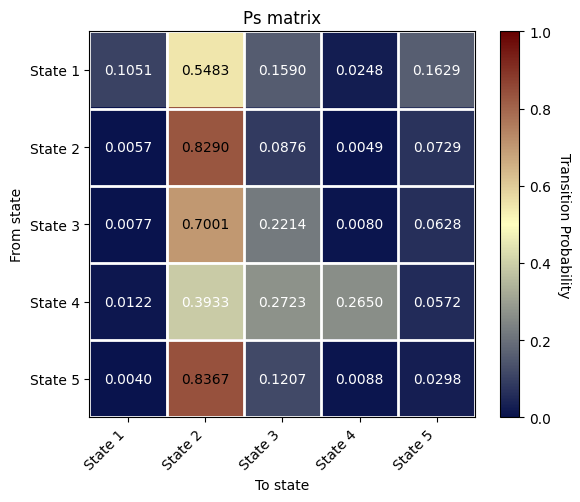

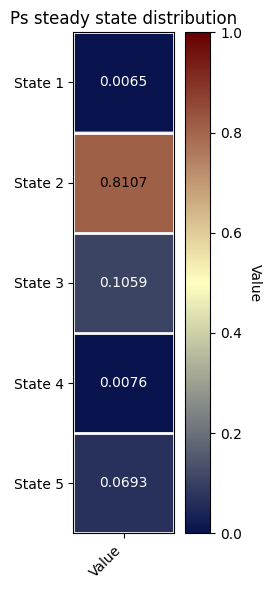

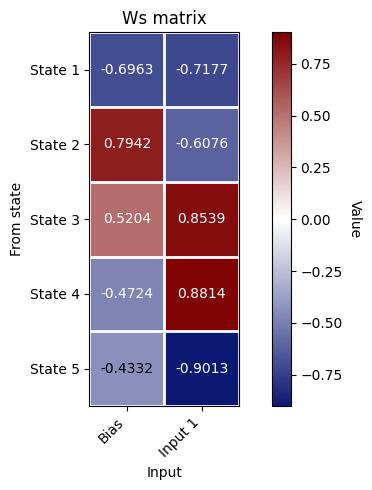

exp Ws: [0.     0.     0.6569 0.3431 0.    ]
Ps@exp Ws: [[0.     0.     0.9247 0.0753 0.    ]
 [0.     0.     0.9716 0.0284 0.    ]
 [0.     0.     0.9814 0.0186 0.    ]
 [0.     0.     0.663  0.337  0.    ]
 [0.     0.     0.9634 0.0366 0.    ]]
[0.     0.     0.9441 0.0559 0.    ]


In [8]:
steady_state_distribution = get_steady_state(mixed_p)
print("Steady-state distribution (non-input P):", steady_state_distribution)

plot_Ps_matrix(mixed_p)
plot_state_vector_heatmap(steady_state_distribution)
plot_Ws_matrix(mixed_ws)

Steady-state distribution (input P): [0.06448653 0.01401824 0.78645687 0.12453858 0.01049978]


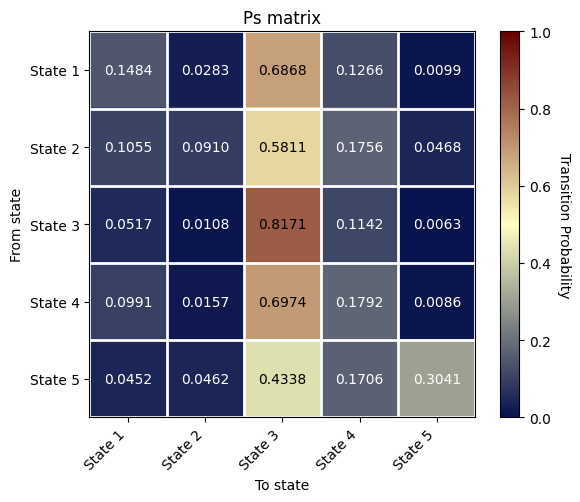

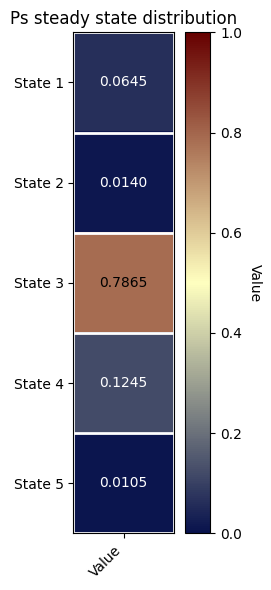

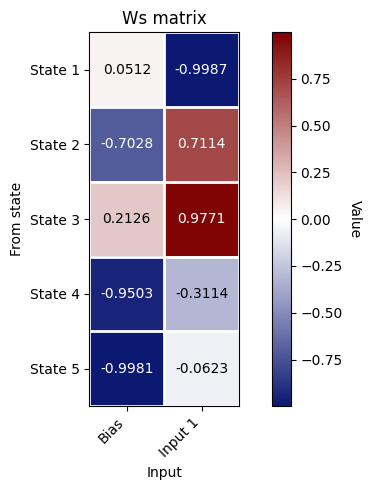

exp Ws: [0.0181 0.     0.9819 0.     0.    ]
Ps@exp Ws: [[0.004  0.     0.996  0.     0.    ]
 [0.0033 0.     0.9967 0.     0.    ]
 [0.0012 0.     0.9988 0.     0.    ]
 [0.0026 0.     0.9974 0.     0.    ]
 [0.0019 0.     0.9981 0.     0.    ]]
[0.0029 0.     0.9971 0.     0.    ]


In [5]:
input_p = np.array([
    [0.14839034, 0.02834622, 0.6868142,  0.12657256, 0.00987665],
    [0.10551982, 0.09095322, 0.58112514, 0.17560269, 0.04679915],
    [0.05165233, 0.01077631, 0.817105,   0.11418615, 0.00628021],
    [0.09909422, 0.01569622, 0.697351,   0.17923212, 0.00862644],
    [0.04521675, 0.04622924, 0.43384826, 0.17056729, 0.3041385]
])

#np.array([[0.19920814, 0.06967026, 0.01152493, 0.6757072, 0.04388937],
#              [0.03341375, 0.21685672, 0.01040104, 0.6531572, 0.08617131],
#              [0.08308174, 0.05830176, 0.16203141, 0.58764946, 0.1089356],
#              [0.05134636, 0.02146791, 0.01433989, 0.890023, 0.0228229],
#              [0.04150027, 0.02520908, 0.02517485, 0.5095464, 0.39856938]])
input_ws = np.array([
    [ 0.05118897, -0.99868894],
    [-0.70275444,  0.7114325],
    [ 0.21255638,  0.9771488],
    [-0.9502642,  -0.31144476],
    [-0.9980552,  -0.06233467]
])
#np.array([[0.47082293, -0.8822277],
#                     [-0.6174176, 0.78663564],
#                     [0.60174674, 0.798687],
#                     [-0.7176737, -0.69637954],
#                     [-0.932004, -0.36244816]])
steady_state_distribution = get_steady_state(input_p)
print("Steady-state distribution (input P):", steady_state_distribution)
plot_Ps_matrix(input_p)
plot_state_vector_heatmap(steady_state_distribution)
plot_Ws_matrix(input_ws)

input_val = 12.5064

with np.printoptions(precision=4, suppress=True):
    inputs = np.array([input_val, 1.])
    print("exp Ws:", np.exp(input_ws@inputs)/np.sum(np.exp(input_ws@inputs)))
    print("Ps@exp Ws:", apply_input(input_p, input_ws, inputs))
    print(np.array([0.5, 0, 0, 0, 0.5])@apply_input(input_p, input_ws, inputs))

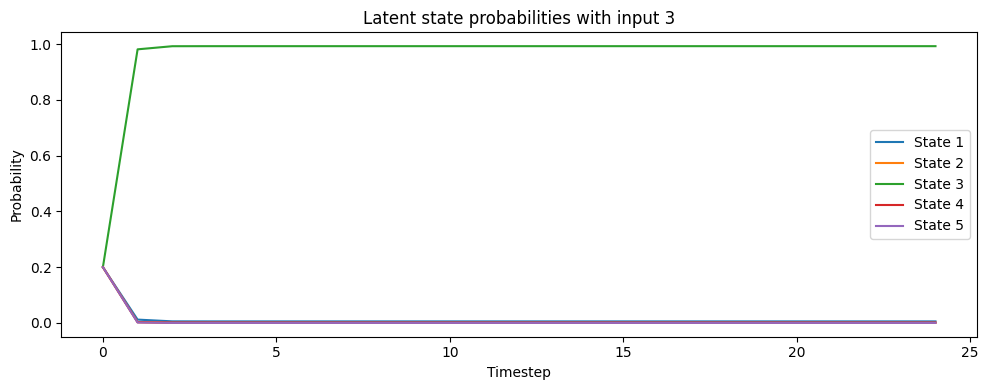

In [6]:
input_p = np.array([
    [0.14839034, 0.02834622, 0.6868142,  0.12657256, 0.00987665],
    [0.10551982, 0.09095322, 0.58112514, 0.17560269, 0.04679915],
    [0.05165233, 0.01077631, 0.817105,   0.11418615, 0.00628021],
    [0.09909422, 0.01569622, 0.697351,   0.17923212, 0.00862644],
    [0.04521675, 0.04622924, 0.43384826, 0.17056729, 0.3041385]
])

#np.array([[0.19920814, 0.06967026, 0.01152493, 0.6757072, 0.04388937],
#              [0.03341375, 0.21685672, 0.01040104, 0.6531572, 0.08617131],
#              [0.08308174, 0.05830176, 0.16203141, 0.58764946, 0.1089356],
#              [0.05134636, 0.02146791, 0.01433989, 0.890023, 0.0228229],
#              [0.04150027, 0.02520908, 0.02517485, 0.5095464, 0.39856938]])
input_ws = np.array([
    [ 0.05118897, -0.99868894],
    [-0.70275444,  0.7114325],
    [ 0.21255638,  0.9771488],
    [-0.9502642,  -0.31144476],
    [-0.9980552,  -0.06233467]
])
#np.array([[0.47082293, -0.8822277],
#                     [-0.6174176, 0.78663564],
#                     [0.60174674, 0.798687],
#                     [-0.7176737, -0.69637954],
#                     [-0.932004, -0.36244816]])

def get_probs_from_input(input_val):
    inputs = np.array([input_val, 1.])

    probs = [np.ones(5)/5]
    input_term = apply_input(input_p, input_ws, inputs)

    for i in range(24):
        probs.append(probs[-1]@input_term)

    return np.asarray(probs).T

def plot_rows(arr, input_name):
    num_rows, num_steps = arr.shape
    x = np.arange(num_steps)

    plt.figure(figsize=(10, 4))
    for i in range(num_rows):
        plt.plot(x, arr[i], label=f"State {i+1}")

    plt.xlabel("Timestep")
    plt.ylabel("Probability")
    plt.title("Latent state probabilities with input " + str(input_name))
    plt.legend()
    plt.tight_layout()
    plt.show()

# Example usage:
input_val = 3
plot_rows(get_probs_from_input(input_val), input_name=input_val)

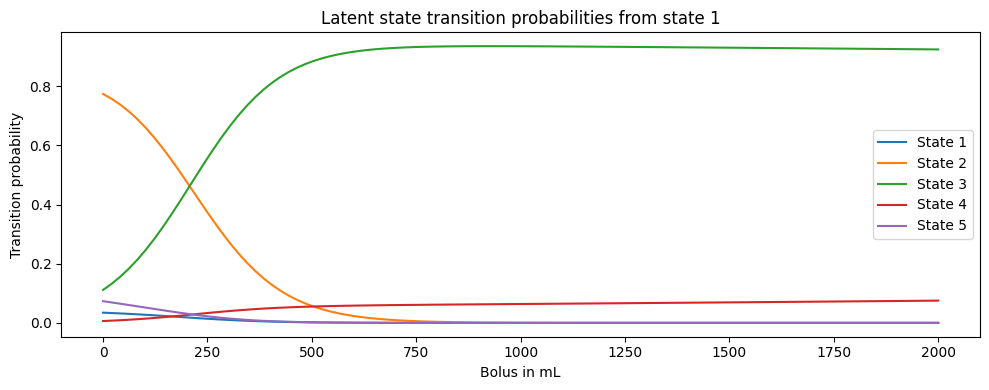

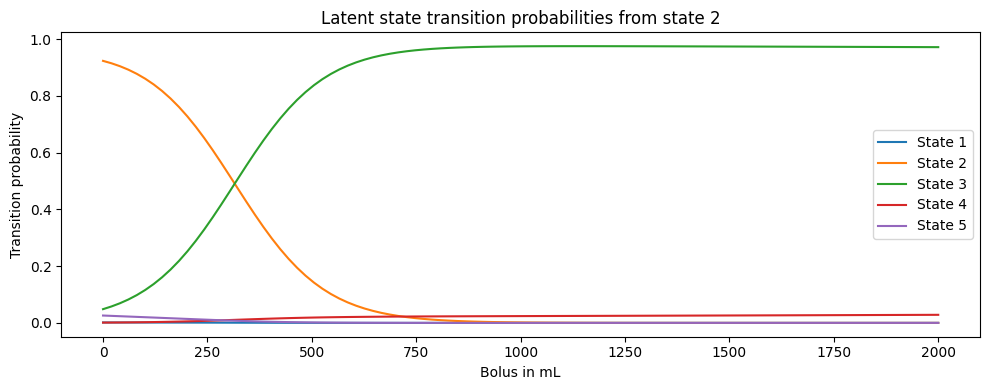

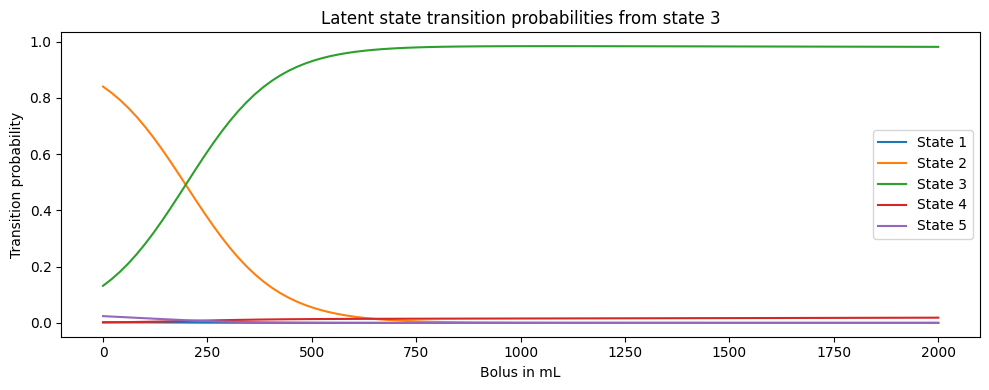

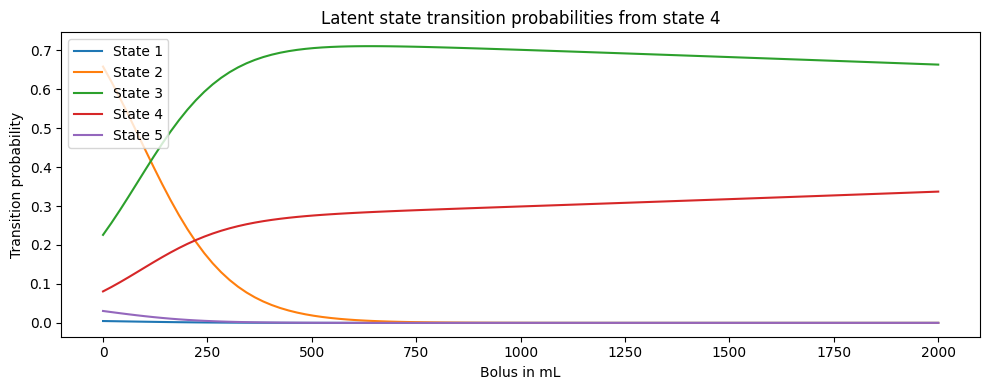

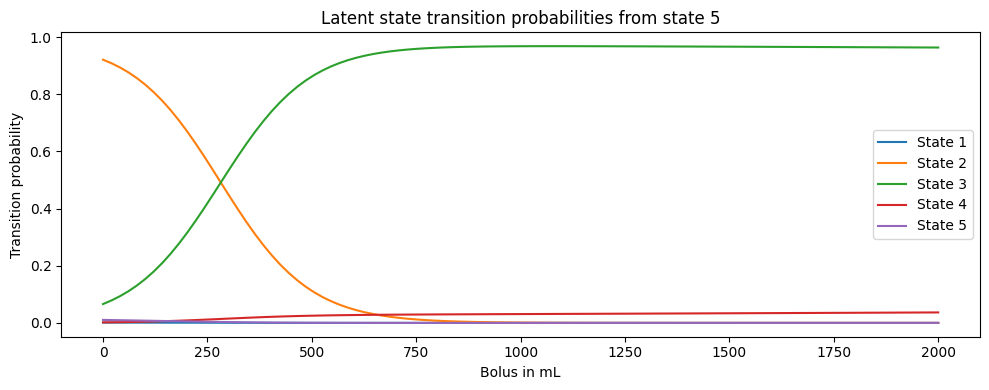

In [15]:
mixed_ws = np.array([
    [-0.6963178,  -0.71773356],
    [ 0.794219,   -0.60763156],
    [ 0.52036136,  0.8539461 ],
    [-0.47238395,  0.8813929 ],
    [-0.43321478, -0.90129066]
])

mixed_p = np.array([
    [0.10507359, 0.5482519,  0.15897389, 0.02477164, 0.16292892],
    [0.00567303, 0.82897615, 0.0875534,  0.00490542, 0.07289199],
    [0.00772088, 0.7000577,  0.22142687, 0.00801758, 0.06277692],
    [0.01219317, 0.39331877, 0.2722827,  0.2649709,  0.05723441],
    [0.00402775, 0.8367175,  0.12068657, 0.00877653, 0.02979166]
])

def get_probs_from_input(input_val):
    inputs = np.array([1, input_val])
    input_ps = apply_input(mixed_p, mixed_ws, inputs)

    return input_ps

def plot_transition_probs(state: int):
    num_rows = 5
    num_steps = 100
    x = np.linspace(0, 2000, num_steps)
    arr = np.stack([get_probs_from_input(val)[state,:] for val in np.linspace(-0.2923, 12.5064, num_steps)]).T#np.linspace(-0.2923, (12.5064+0.2923)/2 - 0.2923, num_steps)]).T

    plt.figure(figsize=(10, 4))
    for i in range(num_rows):
        plt.plot(x, arr[i], label=f"State {i+1}")

    plt.xlabel("Bolus in mL")
    plt.ylabel("Transition probability")
    plt.title("Latent state transition probabilities from state " + str(state + 1))
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_transition_probs(0)
plot_transition_probs(1)
plot_transition_probs(2)
plot_transition_probs(3)
plot_transition_probs(4)

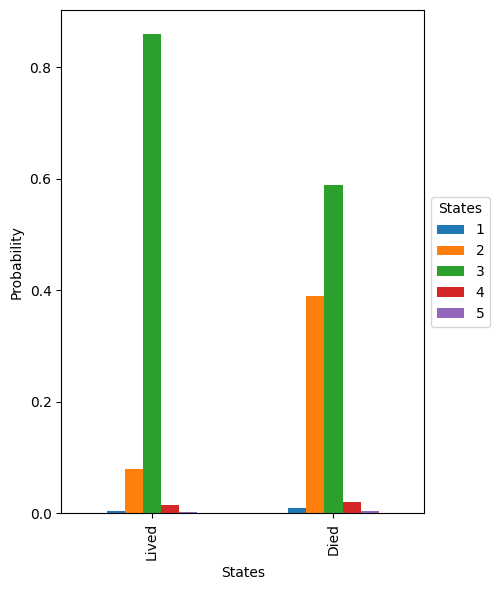

In [14]:
#[0.06, 0.78, 0.04, 0.05, 0.13], [0.28, 0.46, 0.07, 0.06, 0.17]
plot_state_probs([0.005, 0.08, 0.86, 0.015, 0.003], [0.01, 0.39, 0.59, 0.02, 0.004])